In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, zipfile
import pandas as pd

FOLDER = "/content/drive/MyDrive/diabetes_ml_project/"
os.environ["WANDB_MODE"] = "offline"
os.environ["WANDB_DIR"] = FOLDER

with zipfile.ZipFile(FOLDER + "diabetes_raw_dataset.zip") as z:
    with z.open("diabetes_012_health_indicators_BRFSS2015.csv") as f:
        df = pd.read_csv(f)
print(df.shape)

Mounted at /content/drive
(253680, 22)


In [5]:
print(df.columns.tolist())
print(df.dtypes.value_counts())
print("Missing values:", df.isna().sum().sum())

print(df["Diabetes_012"].value_counts().sort_index())
print(df["Diabetes_012"].value_counts(normalize=True).sort_index().round(4))

print("Duplicate rows:", df.duplicated().sum())

print(df.describe().T[["min", "max", "mean"]])

['Diabetes_012', 'HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']
float64    22
Name: count, dtype: int64
Missing values: 0
Diabetes_012
0.0    213703
1.0      4631
2.0     35346
Name: count, dtype: int64
Diabetes_012
0.0    0.8424
1.0    0.0183
2.0    0.1393
Name: proportion, dtype: float64
Duplicate rows: 23899
                       min   max       mean
Diabetes_012           0.0   2.0   0.296921
HighBP                 0.0   1.0   0.429001
HighChol               0.0   1.0   0.424121
CholCheck              0.0   1.0   0.962670
BMI                   12.0  98.0  28.382364
Smoker                 0.0   1.0   0.443169
Stroke                 0.0   1.0   0.040571
HeartDiseaseorAttack   0.0   1.0   0.094186
PhysActivity           0.0   1.0   0.756544
Fruits                 0.0   1.0  

In [2]:
import numpy as np
from sklearn.model_selection import train_test_split

SEED = 42
np.random.seed(SEED)

df_clean = df.drop_duplicates().reset_index(drop=True)
df_clean["Diabetes_012"] = df_clean["Diabetes_012"].astype(int)

print("rows left:", len(df_clean))

rows left: 229781


In [7]:
print(df_clean["Diabetes_012"].value_counts().sort_index())
print(df_clean["Diabetes_012"].value_counts(normalize=True).sort_index().round(4))

Diabetes_012
0    190055
1      4629
2     35097
Name: count, dtype: int64
Diabetes_012
0    0.8271
1    0.0201
2    0.1527
Name: proportion, dtype: float64


In [8]:
print(df_clean["BMI"].quantile([0.5, 0.95, 0.99, 0.999]))
print("BMI above 60:", (df_clean["BMI"] > 60).sum())

0.500    27.00
0.950    40.00
0.990    50.00
0.999    81.22
Name: BMI, dtype: float64
BMI above 60: 805


In [3]:
X = df_clean.drop(columns="Diabetes_012")
y = df_clean["Diabetes_012"]

# 70% for training
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED)

# spliting the remaining 30% evenly into validation and test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

In [10]:
for name, part in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(name, len(part), part.value_counts(normalize=True).sort_index().round(4).tolist())

train 160846 [0.8271, 0.0201, 0.1527]
val 34467 [0.8271, 0.0202, 0.1527]
test 34468 [0.8271, 0.0201, 0.1528]


In [4]:
from sklearn.preprocessing import StandardScaler

bmi_cap = X_train["BMI"].quantile(0.995)
print("BMI cap:", bmi_cap)

X_train_s, X_val_s, X_test_s = X_train.copy(), X_val.copy(), X_test.copy()
for part in (X_train_s, X_val_s, X_test_s):
    part["BMI"] = part["BMI"].clip(upper=bmi_cap)

# only these columns need scaling, the rest are already 0/1
scale_cols = ["BMI", "MentHlth", "PhysHlth", "GenHlth", "Age", "Education", "Income"]

scaler = StandardScaler()
X_train_s[scale_cols] = scaler.fit_transform(X_train_s[scale_cols])
X_val_s[scale_cols] = scaler.transform(X_val_s[scale_cols])
X_test_s[scale_cols] = scaler.transform(X_test_s[scale_cols])

BMI cap: 56.0


In [5]:
from sklearn.metrics import f1_score, recall_score, roc_auc_score, average_precision_score, balanced_accuracy_score

results = []

def evaluate(model, X, y, name):
    proba = model.predict_proba(X)
    pred = proba.argmax(axis=1)
    recalls = recall_score(y, pred, average=None)

    row = {
        "experiment": name,
        "macro_f1": f1_score(y, pred, average="macro"),
        "balanced_acc": balanced_accuracy_score(y, pred),
        "roc_auc_macro": roc_auc_score(y, proba, multi_class="ovr", average="macro"),
        "pr_auc_prediabetes": average_precision_score(y == 1, proba[:, 1]),
        "recall_0": recalls[0],
        "recall_1": recalls[1],
        "recall_2": recalls[2],
    }
    results.append(row)
    return row

In [6]:
from sklearn.linear_model import LogisticRegression

# plain baseline, no tricks for the imbalance yet
lr_base = LogisticRegression(max_iter=1000, random_state=SEED)
lr_base.fit(X_train_s, y_train)

print(evaluate(lr_base, X_val_s, y_val, "E1 LogReg baseline"))

{'experiment': 'E1 LogReg baseline', 'macro_f1': 0.3912350741098895, 'balanced_acc': np.float64(0.38373415045230197), 'roc_auc_macro': np.float64(0.7704486230988331), 'pr_auc_prediabetes': np.float64(0.03508965936441908), 'recall_0': np.float64(0.9754805668584257), 'recall_1': np.float64(0.0), 'recall_2': np.float64(0.17572188449848025)}


In [14]:
lr_bal = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED)
lr_bal.fit(X_train_s, y_train)

print(evaluate(lr_bal, X_val_s, y_val, "E2 LogReg balanced"))

{'experiment': 'E2 LogReg balanced', 'macro_f1': 0.42699109838212806, 'balanced_acc': np.float64(0.5145845259076302), 'roc_auc_macro': np.float64(0.7608320752965626), 'pr_auc_prediabetes': np.float64(0.032786017256304104), 'recall_0': np.float64(0.6445208362564894), 'recall_1': np.float64(0.302158273381295), 'recall_2': np.float64(0.5970744680851063)}


In [15]:
import pandas as pd
pd.DataFrame(results).round(3)

,experiment,macro_f1,balanced_acc,roc_auc_macro,pr_auc_prediabetes,recall_0,recall_1,recall_2
0,E1 LogReg baseline,0.391,0.384,0.770,0.035,0.975,0.000,0.176
1,E2 LogReg balanced,0.427,0.515,0.761,0.033,0.645,0.302,0.597


In [7]:
!pip install -q wandb
import os
os.environ["WANDB_MODE"] = "offline"

In [8]:
import wandb

def log_run(name, config, row):

    run = wandb.init(project="diabetes-ml-vs-dl", name=name, config=config, reinit=True)
    metrics = {k: float(v) for k, v in row.items() if k != "experiment"}
    wandb.log(metrics)
    run.finish()

In [18]:
log_run("E1 LogReg baseline",
        {"model": "LogisticRegression", "class_weight": None, "max_iter": 1000, "split": "70/15/15"},
        results[0])

log_run("E2 LogReg balanced",
        {"model": "LogisticRegression", "class_weight": "balanced", "max_iter": 1000, "split": "70/15/15"},
        results[1])

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.


balanced_acc,▁
macro_f1,▁
pr_auc_prediabetes,▁
recall_0,▁
recall_1,▁
recall_2,▁
roc_auc_macro,▁
balanced_acc,0.38373
macro_f1,0.39124
pr_auc_prediabetes,0.03509
recall_0,0.97548


balanced_acc,▁
macro_f1,▁
pr_auc_prediabetes,▁
recall_0,▁
recall_1,▁
recall_2,▁
roc_auc_macro,▁
balanced_acc,0.51458
macro_f1,0.42699
pr_auc_prediabetes,0.03279
recall_0,0.64452


In [9]:
log_run("E1 LogReg baseline",
        {"model": "LogisticRegression", "class_weight": None, "max_iter": 1000, "split": "70/15/15"},
        results[0])

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.


balanced_acc,▁
macro_f1,▁
pr_auc_prediabetes,▁
recall_0,▁
recall_1,▁
recall_2,▁
roc_auc_macro,▁
balanced_acc,0.38373
macro_f1,0.39124
pr_auc_prediabetes,0.03509
recall_0,0.97548


In [19]:
from sklearn.ensemble import RandomForestClassifier

rf_params = {"n_estimators": 300, "max_depth": 12, "min_samples_leaf": 5,
             "class_weight": "balanced_subsample"}

rf = RandomForestClassifier(**rf_params, n_jobs=-1, random_state=SEED)
rf.fit(X_train_s, y_train)

row = evaluate(rf, X_val_s, y_val, "E3 RandomForest balanced")
log_run("E3 RandomForest balanced", {"model": "RandomForest", **rf_params, "split": "70/15/15"}, row)
print(row)

balanced_acc,▁
macro_f1,▁
pr_auc_prediabetes,▁
recall_0,▁
recall_1,▁
recall_2,▁
roc_auc_macro,▁
balanced_acc,0.5033
macro_f1,0.4384
pr_auc_prediabetes,0.03105
recall_0,0.7084


{'experiment': 'E3 RandomForest balanced', 'macro_f1': 0.43839919253944076, 'balanced_acc': np.float64(0.503302610930405), 'roc_auc_macro': np.float64(0.7548860922651647), 'pr_auc_prediabetes': np.float64(0.031046643190793123), 'recall_0': np.float64(0.7083976427669426), 'recall_1': np.float64(0.08057553956834532), 'recall_2': np.float64(0.7209346504559271)}


In [20]:
from sklearn.ensemble import HistGradientBoostingClassifier

gb_params = {"learning_rate": 0.1, "max_iter": 200, "max_depth": 6,
             "class_weight": "balanced"}

gb = HistGradientBoostingClassifier(**gb_params, random_state=SEED)
gb.fit(X_train_s, y_train)

row = evaluate(gb, X_val_s, y_val, "E4 HistGradBoost balanced")
log_run("E4 HistGradBoost balanced", {"model": "HistGradientBoosting", **gb_params, "split": "70/15/15"}, row)
print(row)

balanced_acc,▁
macro_f1,▁
pr_auc_prediabetes,▁
recall_0,▁
recall_1,▁
recall_2,▁
roc_auc_macro,▁
balanced_acc,0.51219
macro_f1,0.42175
pr_auc_prediabetes,0.03151
recall_0,0.62228


{'experiment': 'E4 HistGradBoost balanced', 'macro_f1': 0.42174776591218394, 'balanced_acc': np.float64(0.5121903352878463), 'roc_auc_macro': np.float64(0.757153080582928), 'pr_auc_prediabetes': np.float64(0.03151092447837845), 'recall_0': np.float64(0.6222814648519713), 'recall_1': np.float64(0.28776978417266186), 'recall_2': np.float64(0.6265197568389058)}


In [21]:
pd.DataFrame(results).round(3)

,experiment,macro_f1,balanced_acc,roc_auc_macro,pr_auc_prediabetes,recall_0,recall_1,recall_2
0,E1 LogReg baseline,0.391,0.384,0.770,0.035,0.975,0.000,0.176
1,E2 LogReg balanced,0.427,0.515,0.761,0.033,0.645,0.302,0.597
2,E3 RandomForest balanced,0.438,0.503,0.755,0.031,0.708,0.081,0.721
3,E4 HistGradBoost balanced,0.422,0.512,0.757,0.032,0.622,0.288,0.627


In [22]:
def add_features(X):
    X = X.copy()
    X["BMI"] = X["BMI"].clip(upper=bmi_cap)
    X["risk_count"] = X[["HighBP", "HighChol", "Stroke", "HeartDiseaseorAttack", "DiffWalk"]].sum(axis=1)
    X["bmi_x_age"] = X["BMI"] * X["Age"]
    X["bad_days"] = X["MentHlth"] + X["PhysHlth"]
    X["habits"] = X[["PhysActivity", "Fruits", "Veggies"]].sum(axis=1) - X["Smoker"] - X["HvyAlcoholConsump"]
    return X

X_train_f, X_val_f, X_test_f = add_features(X_train), add_features(X_val), add_features(X_test)

In [23]:
# scaling the numeric columns plus the new ones
scale_cols_f = scale_cols + ["risk_count", "bmi_x_age", "bad_days", "habits"]
scaler_f = StandardScaler()
X_train_f[scale_cols_f] = scaler_f.fit_transform(X_train_f[scale_cols_f])
X_val_f[scale_cols_f] = scaler_f.transform(X_val_f[scale_cols_f])
X_test_f[scale_cols_f] = scaler_f.transform(X_test_f[scale_cols_f])

In [24]:
# same boosting settings as E4, only the features changed
gb_f = HistGradientBoostingClassifier(**gb_params, random_state=SEED)
gb_f.fit(X_train_f, y_train)

row = evaluate(gb_f, X_val_f, y_val, "E5 HistGradBoost + new features")
log_run("E5 HistGradBoost + new features", {"model": "HistGradientBoosting", **gb_params, "features": "engineered", "split": "70/15/15"}, row)
print(row)

balanced_acc,▁
macro_f1,▁
pr_auc_prediabetes,▁
recall_0,▁
recall_1,▁
recall_2,▁
roc_auc_macro,▁
balanced_acc,0.51188
macro_f1,0.42065
pr_auc_prediabetes,0.03196
recall_0,0.62344


{'experiment': 'E5 HistGradBoost + new features', 'macro_f1': 0.4206489573630045, 'balanced_acc': np.float64(0.5118796366716701), 'roc_auc_macro': np.float64(0.756434478919676), 'pr_auc_prediabetes': np.float64(0.03195880672917529), 'recall_0': np.float64(0.6234390346569384), 'recall_1': np.float64(0.28776978417266186), 'recall_2': np.float64(0.6244300911854104)}


In [10]:
from sklearn.ensemble import HistGradientBoostingClassifier

In [11]:
# smaller trees, slower learning, early stopping to avoid fitting noise
gb2_params = {"learning_rate": 0.05, "max_iter": 500, "max_depth": 4,
              "min_samples_leaf": 50, "l2_regularization": 1.0,
              "early_stopping": True, "validation_fraction": 0.15,
              "n_iter_no_change": 20, "class_weight": "balanced"}

gb2 = HistGradientBoostingClassifier(**gb2_params, random_state=SEED)
gb2.fit(X_train_s, y_train)
print("stopped at iteration:", gb2.n_iter_)

row = evaluate(gb2, X_val_s, y_val, "E6 HistGradBoost regularized")
log_run("E6 HistGradBoost regularized", {"model": "HistGradientBoosting", **gb2_params, "split": "70/15/15"}, row)
print(row)

stopped at iteration: 91


balanced_acc,▁
macro_f1,▁
pr_auc_prediabetes,▁
recall_0,▁
recall_1,▁
recall_2,▁
roc_auc_macro,▁
balanced_acc,0.5157
macro_f1,0.42245
pr_auc_prediabetes,0.03285
recall_0,0.62558


{'experiment': 'E6 HistGradBoost regularized', 'macro_f1': 0.42245395541087466, 'balanced_acc': np.float64(0.5156980925584795), 'roc_auc_macro': np.float64(0.7603187720304524), 'pr_auc_prediabetes': np.float64(0.03285119586560344), 'recall_0': np.float64(0.6255787849024835), 'recall_1': np.float64(0.3079136690647482), 'recall_2': np.float64(0.6136018237082067)}


In [26]:
pd.DataFrame(results).round(3)

,experiment,macro_f1,balanced_acc,roc_auc_macro,pr_auc_prediabetes,recall_0,recall_1,recall_2
0,E1 LogReg baseline,0.391,0.384,0.770,0.035,0.975,0.000,0.176
1,E2 LogReg balanced,0.427,0.515,0.761,0.033,0.645,0.302,0.597
2,E3 RandomForest balanced,0.438,0.503,0.755,0.031,0.708,0.081,0.721
3,E4 HistGradBoost balanced,0.422,0.512,0.757,0.032,0.622,0.288,0.627
4,E5 HistGradBoost + new features,0.421,0.512,0.756,0.032,0.623,0.288,0.624
5,E6 HistGradBoost regularized,0.422,0.516,0.760,0.033,0.626,0.308,0.614


In [27]:
print("E6 trees used:", gb2.n_iter_)

E6 trees used: 91


In [28]:
# probabilities from the baseline model
proba_val = lr_base.predict_proba(X_val_s)

# half of validation to tune on, half to check on
idx_tune, idx_check = train_test_split(
    np.arange(len(y_val)), test_size=0.5, stratify=y_val, random_state=SEED)
y_tune = y_val.values[idx_tune]
y_check = y_val.values[idx_check]

In [29]:
# multiplying each class probability by a weight, then picking the biggest
def predict_with_weights(proba, w1, w2):
    return (proba * np.array([1, w1, w2])).argmax(axis=1)

best_score, best_w = 0, None
for w1 in [1, 2, 4, 6, 8, 10, 15, 20, 30]:
    for w2 in [1, 1.5, 2, 3, 4, 5, 6]:
        pred = predict_with_weights(proba_val[idx_tune], w1, w2)
        score = f1_score(y_tune, pred, average="macro")
        if score > best_score:
            best_score, best_w = score, (w1, w2)

print("best weights:", best_w, "macro_f1 on tuning half:", round(best_score, 3))

best weights: (20, 3) macro_f1 on tuning half: 0.461


In [12]:
def evaluate_proba(proba, y, name, w=(1, 1, 1)):
    pred = (proba * np.array(w)).argmax(axis=1)
    recalls = recall_score(y, pred, average=None)
    row = {
        "experiment": name,
        "macro_f1": f1_score(y, pred, average="macro"),
        "balanced_acc": balanced_accuracy_score(y, pred),
        "roc_auc_macro": roc_auc_score(y, proba, multi_class="ovr", average="macro"),
        "pr_auc_prediabetes": average_precision_score(y == 1, proba[:, 1]),
        "recall_0": recalls[0],
        "recall_1": recalls[1],
        "recall_2": recalls[2],
    }
    results.append(row)
    return row

In [13]:
import matplotlib.pyplot as plt

In [31]:
# same half, no tuning, so the comparison is fair
ref = evaluate_proba(proba_val[idx_check], y_check, "E7ref LogReg no tuning (check half)")

# same half, with the tuned weights
tuned = evaluate_proba(proba_val[idx_check], y_check, "E7 LogReg + tuned thresholds (check half)", w=(1, *best_w))
log_run("E7 LogReg + tuned thresholds",
        {"model": "LogisticRegression", "class_weight": None, "tuned_weights": best_w, "split": "70/15/15, val halved"},
        tuned)

print(pd.DataFrame([ref, tuned]).round(3))

balanced_acc,▁
macro_f1,▁
pr_auc_prediabetes,▁
recall_0,▁
recall_1,▁
recall_2,▁
roc_auc_macro,▁
balanced_acc,0.47302
macro_f1,0.45589
pr_auc_prediabetes,0.03527
recall_0,0.84355


                                  experiment  macro_f1  balanced_acc  \
0        E7ref LogReg no tuning (check half)     0.391         0.384   
1  E7 LogReg + tuned thresholds (check half)     0.456         0.473   

   roc_auc_macro  pr_auc_prediabetes  recall_0  recall_1  recall_2  
0          0.774               0.035     0.978     0.000     0.173  
1          0.774               0.035     0.844     0.034     0.541  


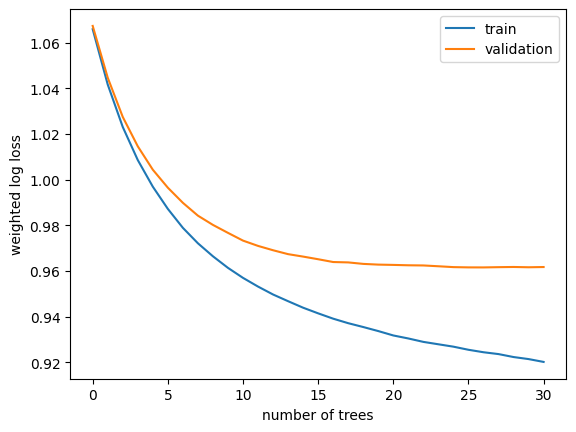

best tree count on validation: 27


In [32]:
from sklearn.metrics import log_loss
from sklearn.utils.class_weight import compute_sample_weight

# weight the loss the same way the model was trained (balanced classes)
w_train = compute_sample_weight("balanced", y_train)
w_val = compute_sample_weight("balanced", y_val)

train_loss, val_loss = [], []
for p_tr, p_va in zip(gb.staged_predict_proba(X_train_s), gb.staged_predict_proba(X_val_s)):
    train_loss.append(log_loss(y_train, p_tr, sample_weight=w_train))
    val_loss.append(log_loss(y_val, p_va, sample_weight=w_val))

import matplotlib.pyplot as plt
plt.plot(train_loss, label="train")
plt.plot(val_loss, label="validation")
plt.xlabel("number of trees")
plt.ylabel("weighted log loss")
plt.legend()
plt.show()

print("best tree count on validation:", int(np.argmin(val_loss)) + 1)

In [33]:
print("E4 trees used:", gb.n_iter_)

E4 trees used: 31


In [14]:
# rows = true class, columns = predicted class
# the numbers are assumed costs, a missed diabetes case is the worst error
cost = np.array([
    [0, 1, 1],    # truly healthy: a false alarm costs 1
    [3, 0, 1],    # truly prediabetes: missing it costs 3
    [10, 3, 0],   # truly diabetes: missing it costs 10
])

In [15]:
# for each person, we pick the prediction with the lowest expected cost
def predict_min_cost(proba, cost):
    return (proba @ cost).argmin(axis=1)

def avg_cost(y, pred, cost):
    return cost[np.asarray(y), pred].mean()

In [36]:
p_base = lr_base.predict_proba(X_val_s)
p_bal = lr_bal.predict_proba(X_val_s)

options = {
    "E1 baseline argmax": p_base.argmax(axis=1),
    "E2 balanced argmax": p_bal.argmax(axis=1),
    "E7b baseline + min cost": predict_min_cost(p_base, cost),
}

rows = []
for name, pred in options.items():
    rec = recall_score(y_val, pred, average=None)
    rows.append({"setup": name, "avg_cost": avg_cost(y_val, pred, cost),
                 "macro_f1": f1_score(y_val, pred, average="macro"),
                 "recall_0": rec[0], "recall_1": rec[1], "recall_2": rec[2]})
pd.DataFrame(rows).round(3)

,setup,avg_cost,macro_f1,recall_0,recall_1,recall_2
0,E1 baseline argmax,1.336,0.391,0.975,0.000,0.176
1,E2 balanced argmax,0.687,0.427,0.645,0.302,0.597
2,E7b baseline + min cost,0.552,0.365,0.542,0.000,0.906


In [37]:
pred_mc = predict_min_cost(p_base, cost)
print("true prediabetes predicted as 0/1/2:", np.bincount(pred_mc[y_val.values == 1], minlength=3))

true prediabetes predicted as 0/1/2: [154   0 541]


In [38]:
def make_cost(fn):
    return np.array([[0, 1, 1],
                     [fn * 0.3, 0, 1],
                     [fn, fn * 0.3, 0]])

In [39]:
yv = y_val.values
rows = []
for fn in [2, 5, 10, 20, 40]:
    c = make_cost(fn)
    pred_mc = predict_min_cost(p_base, c)
    rows.append({
        "miss_diabetes_cost": fn,
        "cost_E1": avg_cost(yv, p_base.argmax(axis=1), c),
        "cost_E2": avg_cost(yv, p_bal.argmax(axis=1), c),
        "cost_min": avg_cost(yv, pred_mc, c),
        "healthy_flagged": (pred_mc[yv == 0] != 0).mean(),
        "diabetes_caught": (pred_mc[yv == 2] == 2).mean(),
        "prediabetes_flagged": (pred_mc[yv == 1] != 0).mean(),
    })
pd.DataFrame(rows).round(3)

,miss_diabetes_cost,cost_E1,cost_E2,cost_min,healthy_flagged,diabetes_caught,prediabetes_flagged
0,2,0.285,0.379,0.263,0.083,0.407,0.229
1,5,0.679,0.494,0.435,0.263,0.747,0.600
2,10,1.336,0.687,0.552,0.458,0.906,0.778
3,20,2.650,1.071,0.657,0.659,0.972,0.929
4,40,5.279,1.840,0.743,0.831,0.995,0.981


In [40]:
!pip install -q imbalanced-learn

In [41]:
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTENC

X_tr_clip = X_train.copy()
X_tr_clip["BMI"] = X_tr_clip["BMI"].clip(upper=bmi_cap)

def scale_like_train(X):
    X = X.copy()
    X[scale_cols] = scaler.transform(X[scale_cols])
    return X

In [42]:
# E8a: undersampling every class down to the size of the smallest one
Xr, yr = RandomUnderSampler(random_state=SEED).fit_resample(X_tr_clip, y_train)
print(yr.value_counts().sort_index().tolist())

lr_us = LogisticRegression(max_iter=1000, random_state=SEED)
lr_us.fit(scale_like_train(Xr), yr)

row = evaluate(lr_us, X_val_s, y_val, "E8a LogReg undersampled")
log_run("E8a LogReg undersampled", {"model": "LogisticRegression", "resampling": "random undersample to smallest class"}, row)
print(row)

[3240, 3240, 3240]


balanced_acc,▁
macro_f1,▁
pr_auc_prediabetes,▁
recall_0,▁
recall_1,▁
recall_2,▁
roc_auc_macro,▁
balanced_acc,0.51459
macro_f1,0.42508
pr_auc_prediabetes,0.03222
recall_0,0.63982


{'experiment': 'E8a LogReg undersampled', 'macro_f1': 0.4250794618502686, 'balanced_acc': np.float64(0.5145937786288847), 'roc_auc_macro': np.float64(0.7588391522533452), 'pr_auc_prediabetes': np.float64(0.032218664966708985), 'recall_0': np.float64(0.6398204012908657), 'recall_1': np.float64(0.3194244604316547), 'recall_2': np.float64(0.5845364741641338)}


In [43]:
# E8b: SMOTENC makes synthetic rows for the rare classes
cat_names = ["HighBP", "HighChol", "CholCheck", "Smoker", "Stroke", "HeartDiseaseorAttack",
             "PhysActivity", "Fruits", "Veggies", "HvyAlcoholConsump", "AnyHealthcare",
             "NoDocbcCost", "DiffWalk", "Sex"]
cat_idx = [X_tr_clip.columns.get_loc(c) for c in cat_names]

smote = SMOTENC(categorical_features=cat_idx, sampling_strategy={1: 20000, 2: 40000}, random_state=SEED)
Xs, ys = smote.fit_resample(X_tr_clip, y_train)
print(ys.value_counts().sort_index().tolist())

lr_sm = LogisticRegression(max_iter=1000, random_state=SEED)
lr_sm.fit(scale_like_train(Xs), ys)

row = evaluate(lr_sm, X_val_s, y_val, "E8b LogReg SMOTENC")
log_run("E8b LogReg SMOTENC", {"model": "LogisticRegression", "resampling": "SMOTENC, class1=20000, class2=40000"}, row)
print(row)

[133038, 20000, 40000]


balanced_acc,▁
macro_f1,▁
pr_auc_prediabetes,▁
recall_0,▁
recall_1,▁
recall_2,▁
roc_auc_macro,▁
balanced_acc,0.4259
macro_f1,0.43324
pr_auc_prediabetes,0.03111
recall_0,0.93539


{'experiment': 'E8b LogReg SMOTENC', 'macro_f1': 0.43324349355306196, 'balanced_acc': np.float64(0.42590392870754634), 'roc_auc_macro': np.float64(0.7503680696111791), 'pr_auc_prediabetes': np.float64(0.03110859998879771), 'recall_0': np.float64(0.9353865581591132), 'recall_1': np.float64(0.0), 'recall_2': np.float64(0.3423252279635258)}


In [44]:
pd.DataFrame(results).round(3)

,experiment,macro_f1,balanced_acc,roc_auc_macro,pr_auc_prediabetes,recall_0,recall_1,recall_2
0,E1 LogReg baseline,0.391,0.384,0.770,0.035,0.975,0.000,0.176
1,E2 LogReg balanced,0.427,0.515,0.761,0.033,0.645,0.302,0.597
2,E3 RandomForest balanced,0.438,0.503,0.755,0.031,0.708,0.081,0.721
3,E4 HistGradBoost balanced,0.422,0.512,0.757,0.032,0.622,0.288,0.627
4,E5 HistGradBoost + new features,0.421,0.512,0.756,0.032,0.623,0.288,0.624
5,E6 HistGradBoost regularized,0.422,0.516,0.760,0.033,0.626,0.308,0.614
6,E7ref LogReg no tuning (check half),0.391,0.384,0.774,0.035,0.978,0.000,0.173
7,E7 LogReg + tuned thresholds (check half),0.456,0.473,0.774,0.035,0.844,0.034,0.541
8,E8a LogReg undersampled,0.425,0.515,0.759,0.032,0.640,0.319,0.585
9,E8b LogReg SMOTENC,0.433,0.426,0.750,0.031,0.935,0.000,0.342


In [45]:
p = lr_base.predict_proba(X_val_s)
for k in range(3):
    print("class", k, "one-vs-rest AUC:", round(roc_auc_score(y_val == k, p[:, k]), 3))

class 0 one-vs-rest AUC: 0.81
class 1 one-vs-rest AUC: 0.687
class 2 one-vs-rest AUC: 0.815


In [46]:
from sklearn.metrics import precision_score

y_train_b = (y_train > 0).astype(int)
y_val_b = (y_val > 0).astype(int)
print("positive share in train:", round(y_train_b.mean(), 3))

positive share in train: 0.173


In [47]:
results_bin = []

def evaluate_bin(model, X, y, name):
    proba = model.predict_proba(X)[:, 1]
    pred = (proba >= 0.5).astype(int)
    row = {"experiment": name,
           "roc_auc": roc_auc_score(y, proba),
           "pr_auc": average_precision_score(y, proba),
           "precision": precision_score(y, pred),
           "recall": recall_score(y, pred),
           "f1": f1_score(y, pred),
           "balanced_acc": balanced_accuracy_score(y, pred)}
    results_bin.append(row)
    return row

In [48]:
# E9a: balanced logistic regression
lr_b = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED)
lr_b.fit(X_train_s, y_train_b)

row = evaluate_bin(lr_b, X_val_s, y_val_b, "E9a binary LogReg balanced")
log_run("E9a binary LogReg balanced", {"model": "LogisticRegression", "target": "binary", "class_weight": "balanced"}, row)
print(row)

balanced_acc,▁
f1,▁
pr_auc,▁
precision,▁
recall,▁
roc_auc,▁
balanced_acc,0.73648
f1,0.48521
pr_auc,0.45212
precision,0.35643
recall,0.75969


{'experiment': 'E9a binary LogReg balanced', 'roc_auc': np.float64(0.8096919291553882), 'pr_auc': np.float64(0.4521226125389773), 'precision': 0.3564286276671128, 'recall': 0.7596912233596241, 'f1': 0.4852090032154341, 'balanced_acc': np.float64(0.7364823452282897)}


In [49]:
# E9b: boosting with the same settings as E6
gb_b = HistGradientBoostingClassifier(**gb2_params, random_state=SEED)
gb_b.fit(X_train_s, y_train_b)

row = evaluate_bin(gb_b, X_val_s, y_val_b, "E9b binary HistGradBoost regularized")
log_run("E9b binary HistGradBoost regularized", {"model": "HistGradientBoosting", "target": "binary", **gb2_params}, row)
print(row)

balanced_acc,▁
f1,▁
pr_auc,▁
precision,▁
recall,▁
roc_auc,▁
balanced_acc,0.74072
f1,0.48556
pr_auc,0.47567
precision,0.35195
recall,0.78268


{'experiment': 'E9b binary HistGradBoost regularized', 'roc_auc': np.float64(0.8158640130409865), 'pr_auc': np.float64(0.4756661182519406), 'precision': 0.35194687594325386, 'recall': 0.7826816579963081, 'f1': 0.4855551506949144, 'balanced_acc': np.float64(0.7407164428609294)}


In [50]:
pd.DataFrame(results_bin).round(3)

,experiment,roc_auc,pr_auc,precision,recall,f1,balanced_acc
0,E9a binary LogReg balanced,0.810,0.452,0.356,0.760,0.485,0.736
1,E9b binary HistGradBoost regularized,0.816,0.476,0.352,0.783,0.486,0.741


In [16]:
!pip install -q tensorflow

In [17]:
import tensorflow as tf
from sklearn.utils.class_weight import compute_sample_weight

tf.keras.utils.set_random_seed(SEED)

def make_ds(X, y, shuffle=False, batch=256):
    w = compute_sample_weight("balanced", y).astype("float32")
    ds = tf.data.Dataset.from_tensor_slices(
        (X.values.astype("float32"), y.values.astype("int32"), w))
    if shuffle:
        ds = ds.shuffle(10000, seed=SEED)
    return ds.batch(batch).prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(X_train_s, y_train, shuffle=True)
val_ds = make_ds(X_val_s, y_val)

In [18]:
def build_model(n_features, units=(64, 32), dropout=0.3, lr=1e-3):
    model = tf.keras.Sequential([tf.keras.layers.Input(shape=(n_features,))])
    for u in units:
        model.add(tf.keras.layers.Dense(u, activation="relu"))
        model.add(tf.keras.layers.Dropout(dropout))
    model.add(tf.keras.layers.Dense(3, activation="softmax"))
    model.compile(optimizer=tf.keras.optimizers.Adam(lr),
                  loss="sparse_categorical_crossentropy")
    return model

In [54]:
# E10: first neural network, stops itself when validation loss stops improving
nn_params = {"units": (64, 32), "dropout": 0.3, "lr": 1e-3}
nn = build_model(X_train_s.shape[1], **nn_params)

stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5,
                                        restore_best_weights=True)
hist = nn.fit(train_ds, validation_data=val_ds, epochs=50, callbacks=[stop], verbose=2)
print("epochs run:", len(hist.history["loss"]))

Epoch 1/50
629/629 - 9s - 14ms/step - loss: 1.0159 - val_loss: 0.9696
Epoch 2/50
629/629 - 4s - 6ms/step - loss: 0.9865 - val_loss: 0.9645
Epoch 3/50
629/629 - 6s - 9ms/step - loss: 0.9810 - val_loss: 0.9649
Epoch 4/50
629/629 - 3s - 4ms/step - loss: 0.9787 - val_loss: 0.9633
Epoch 5/50
629/629 - 3s - 4ms/step - loss: 0.9744 - val_loss: 0.9630
Epoch 6/50
629/629 - 6s - 9ms/step - loss: 0.9755 - val_loss: 0.9614
Epoch 7/50
629/629 - 4s - 6ms/step - loss: 0.9730 - val_loss: 0.9632
Epoch 8/50
629/629 - 2s - 4ms/step - loss: 0.9737 - val_loss: 0.9622
Epoch 9/50
629/629 - 3s - 4ms/step - loss: 0.9709 - val_loss: 0.9610
Epoch 10/50
629/629 - 2s - 4ms/step - loss: 0.9702 - val_loss: 0.9609
Epoch 11/50
629/629 - 3s - 5ms/step - loss: 0.9690 - val_loss: 0.9617
Epoch 12/50
629/629 - 4s - 7ms/step - loss: 0.9675 - val_loss: 0.9609
Epoch 13/50
629/629 - 2s - 4ms/step - loss: 0.9681 - val_loss: 0.9626
Epoch 14/50
629/629 - 2s - 4ms/step - loss: 0.9660 - val_loss: 0.9636
Epoch 15/50
629/629 - 3s - 5

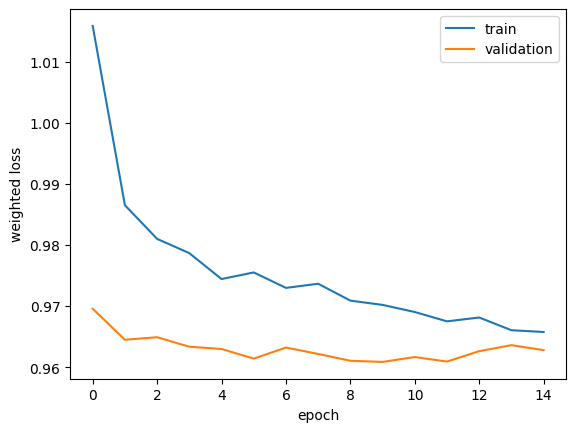

In [55]:
# learning curve
plt.plot(hist.history["loss"], label="train")
plt.plot(hist.history["val_loss"], label="validation")
plt.xlabel("epoch")
plt.ylabel("weighted loss")
plt.legend()
plt.show()

In [56]:
proba_nn = nn.predict(X_val_s.values.astype("float32"), batch_size=1024)
row = evaluate_proba(proba_nn, y_val, "E10 Keras 64-32 dropout 0.3")
log_run("E10 Keras 64-32 dropout 0.3",
        {"model": "Keras Sequential", **nn_params, "batch": 256, "sample_weights": "balanced", "split": "70/15/15"},
        row)
print(row)

34/34 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step


balanced_acc,▁
macro_f1,▁
pr_auc_prediabetes,▁
recall_0,▁
recall_1,▁
recall_2,▁
roc_auc_macro,▁
balanced_acc,0.5136
macro_f1,0.42737
pr_auc_prediabetes,0.03155
recall_0,0.64214


{'experiment': 'E10 Keras 64-32 dropout 0.3', 'macro_f1': 0.42737362174579124, 'balanced_acc': np.float64(0.5136017356638785), 'roc_auc_macro': np.float64(0.7622329791668937), 'pr_auc_prediabetes': np.float64(0.0315464026725101), 'recall_0': np.float64(0.6421355409007998), 'recall_1': np.float64(0.2446043165467626), 'recall_2': np.float64(0.6540653495440729)}


In [23]:
def run_nn(name, units, dropout, lr, batch):
    tf.keras.utils.set_random_seed(SEED)

    # rebuilding the datasets so the batch size can change between experiments
    tr = make_ds(X_train_s, y_train, shuffle=True, batch=batch)
    va = make_ds(X_val_s, y_val, batch=batch)

    model = build_model(X_train_s.shape[1], units=units, dropout=dropout, lr=lr)
    stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5,
                                            restore_best_weights=True)
    h = model.fit(tr, validation_data=va, epochs=50, callbacks=[stop], verbose=0)

    best_epoch = int(np.argmin(h.history["val_loss"])) + 1
    print("epochs run:", len(h.history["loss"]), "| best epoch:", best_epoch,
          "| best val loss:", round(min(h.history["val_loss"]), 4))

    plt.plot(h.history["loss"], label="train")
    plt.plot(h.history["val_loss"], label="validation")
    plt.xlabel("epoch")
    plt.ylabel("weighted loss")
    plt.title(name)
    plt.legend()

    # saving the figure into the Drive folder
    plt.savefig(FOLDER + name.replace(" ", "_") + ".png", dpi=200, bbox_inches="tight")
    plt.show()

    proba = model.predict(X_val_s.values.astype("float32"), batch_size=1024, verbose=0)
    row = evaluate_proba(proba, y_val, name)
    log_run(name, {"model": "Keras Sequential", "units": units, "dropout": dropout,
                   "lr": lr, "batch": batch, "sample_weights": "balanced",
                   "epochs_run": len(h.history["loss"]), "split": "70/15/15"}, row)
    return model, h, row

In [24]:
import matplotlib.pyplot as plt

epochs run: 25 | best epoch: 20 | best val loss: 0.9621


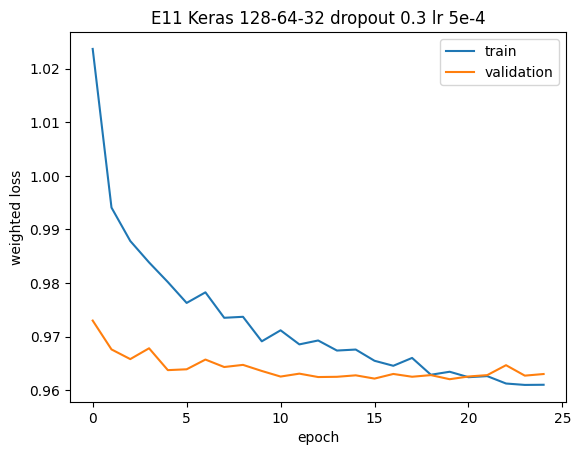

balanced_acc,▁
macro_f1,▁
pr_auc_prediabetes,▁
recall_0,▁
recall_1,▁
recall_2,▁
roc_auc_macro,▁
balanced_acc,0.51316
macro_f1,0.42326
pr_auc_prediabetes,0.03129
recall_0,0.62347


{'experiment': 'E11 Keras 128-64-32 dropout 0.3 lr 5e-4', 'macro_f1': 0.42326267138026474, 'balanced_acc': np.float64(0.5131554244028561), 'roc_auc_macro': np.float64(0.7593908228476577), 'pr_auc_prediabetes': np.float64(0.03128787101186927), 'recall_0': np.float64(0.6234741125298162), 'recall_1': np.float64(0.26762589928057556), 'recall_2': np.float64(0.6483662613981763)}


In [25]:
nn11, h11, row11 = run_nn("E11 Keras 128-64-32 dropout 0.3 lr 5e-4",
                          units=(128, 64, 32), dropout=0.3, lr=5e-4, batch=256)
print(row11)

epochs run: 20 | best epoch: 15 | best val loss: 0.9604


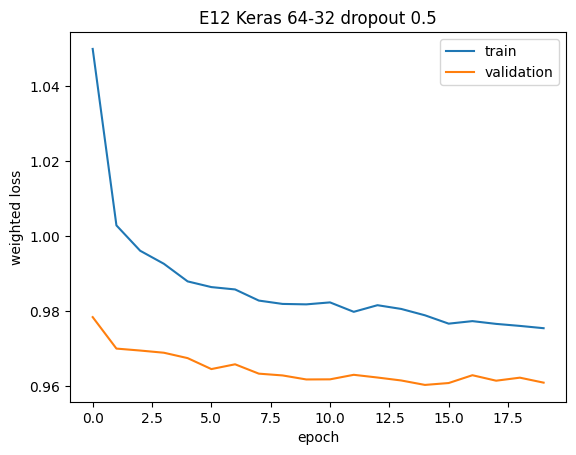

balanced_acc,▁
macro_f1,▁
pr_auc_prediabetes,▁
recall_0,▁
recall_1,▁
recall_2,▁
roc_auc_macro,▁
balanced_acc,0.51804
macro_f1,0.43211
pr_auc_prediabetes,0.03288
recall_0,0.65112


{'experiment': 'E12 Keras 64-32 dropout 0.5', 'macro_f1': 0.4321062915924229, 'balanced_acc': np.float64(0.5180385431421826), 'roc_auc_macro': np.float64(0.7665890801904401), 'pr_auc_prediabetes': np.float64(0.032883680576433996), 'recall_0': np.float64(0.6511154763575137), 'recall_1': np.float64(0.21151079136690648), 'recall_2': np.float64(0.6914893617021277)}


In [26]:
nn12, h12, row12 = run_nn("E12 Keras 64-32 dropout 0.5",
                          units=(64, 32), dropout=0.5, lr=1e-3, batch=256)
print(row12)

In [60]:
pd.DataFrame(results).round(3)

,experiment,macro_f1,balanced_acc,roc_auc_macro,pr_auc_prediabetes,recall_0,recall_1,recall_2
0,E1 LogReg baseline,0.391,0.384,0.770,0.035,0.975,0.000,0.176
1,E2 LogReg balanced,0.427,0.515,0.761,0.033,0.645,0.302,0.597
2,E3 RandomForest balanced,0.438,0.503,0.755,0.031,0.708,0.081,0.721
3,E4 HistGradBoost balanced,0.422,0.512,0.757,0.032,0.622,0.288,0.627
4,E5 HistGradBoost + new features,0.421,0.512,0.756,0.032,0.623,0.288,0.624
5,E6 HistGradBoost regularized,0.422,0.516,0.760,0.033,0.626,0.308,0.614
6,E7ref LogReg no tuning (check half),0.391,0.384,0.774,0.035,0.978,0.000,0.173
7,E7 LogReg + tuned thresholds (check half),0.456,0.473,0.774,0.035,0.844,0.034,0.541
8,E8a LogReg undersampled,0.425,0.515,0.759,0.032,0.640,0.319,0.585
9,E8b LogReg SMOTENC,0.433,0.426,0.750,0.031,0.935,0.000,0.342


In [61]:
# the weights found in E7
print("best weights:", best_w)

print("SMOTENC counts:", ys.value_counts().sort_index().tolist())

p = lr_base.predict_proba(X_val_s)
for k in range(3):
    print("class", k, "one-vs-rest AUC:", round(roc_auc_score(y_val == k, p[:, k]), 3))

best weights: (20, 3)
SMOTENC counts: [133038, 20000, 40000]
class 0 one-vs-rest AUC: 0.81
class 1 one-vs-rest AUC: 0.687
class 2 one-vs-rest AUC: 0.815


In [62]:
pred_mc = predict_min_cost(p_base, cost)
rec = recall_score(y_val, pred_mc, average=None)
row_e7b = {"macro_f1": f1_score(y_val, pred_mc, average="macro"),
           "avg_cost": avg_cost(y_val, pred_mc, cost),
           "recall_0": rec[0], "recall_1": rec[1], "recall_2": rec[2]}
log_run("E7b LogReg + min expected cost",
        {"model": "LogisticRegression", "cost_matrix": cost.tolist(), "costs": "assumed"}, row_e7b)

avg_cost,▁
macro_f1,▁
recall_0,▁
recall_1,▁
recall_2,▁
avg_cost,0.55154
macro_f1,0.36533
recall_0,0.54164
recall_1,0
recall_2,0.90616


In [63]:
def make_ds_bin(X, y, shuffle=False, batch=256):
    w = compute_sample_weight("balanced", y).astype("float32")
    ds = tf.data.Dataset.from_tensor_slices(
        (X.values.astype("float32"), y.values.astype("int32"), w))
    if shuffle:
        ds = ds.shuffle(10000, seed=SEED)
    return ds.batch(batch).prefetch(tf.data.AUTOTUNE)

train_b = make_ds_bin(X_train_s, y_train_b, shuffle=True)
val_b = make_ds_bin(X_val_s, y_val_b)

In [64]:
# same shape as E12 (best dropout), but one sigmoid output
tf.keras.utils.set_random_seed(SEED)
nn_b = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train_s.shape[1],)),
    tf.keras.layers.Dense(64, activation="relu"), tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(32, activation="relu"), tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(1, activation="sigmoid")])
nn_b.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="binary_crossentropy")

stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
hb = nn_b.fit(train_b, validation_data=val_b, epochs=50, callbacks=[stop], verbose=0)
print("epochs run:", len(hb.history["loss"]), "| best val loss:", round(min(hb.history["val_loss"]), 4))

epochs run: 29 | best val loss: 0.5233


In [65]:
# score like E9 (0.5 cutoff)
proba_b = nn_b.predict(X_val_s.values.astype("float32"), batch_size=1024, verbose=0).ravel()
pred_b = (proba_b >= 0.5).astype(int)
row = {"experiment": "E13 binary Keras 64-32 dropout 0.5",
       "roc_auc": roc_auc_score(y_val_b, proba_b), "pr_auc": average_precision_score(y_val_b, proba_b),
       "precision": precision_score(y_val_b, pred_b), "recall": recall_score(y_val_b, pred_b),
       "f1": f1_score(y_val_b, pred_b), "balanced_acc": balanced_accuracy_score(y_val_b, pred_b)}
results_bin.append(row)
log_run("E13 binary Keras", {"model": "Keras Sequential", "target": "binary", "dropout": 0.5}, row)
pd.DataFrame(results_bin).round(3)

balanced_acc,▁
f1,▁
pr_auc,▁
precision,▁
recall,▁
roc_auc,▁
balanced_acc,0.74145
f1,0.48619
pr_auc,0.46835
precision,0.35228
recall,0.78436


,experiment,roc_auc,pr_auc,precision,recall,f1,balanced_acc
0,E9a binary LogReg balanced,0.810,0.452,0.356,0.760,0.485,0.736
1,E9b binary HistGradBoost regularized,0.816,0.476,0.352,0.783,0.486,0.741
2,E13 binary Keras 64-32 dropout 0.5,0.816,0.468,0.352,0.784,0.486,0.741


In [27]:
p_lr = lr_base.predict_proba(X_test_s)
p_gb = gb2.predict_proba(X_test_s)
p_nn = nn12.predict(X_test_s.values.astype("float32"), batch_size=1024, verbose=0)
yt = y_test.values

In [28]:
# LR uses the cost rule, the other two use their normal argmax
preds = {
    "LogReg + min cost": predict_min_cost(p_lr, cost),
    "HistGradBoost E6": p_gb.argmax(axis=1),
    "Keras E12": p_nn.argmax(axis=1),
}
probas = {"LogReg + min cost": p_lr, "HistGradBoost E6": p_gb, "Keras E12": p_nn}

rows = []
for name in preds:
    rec = recall_score(yt, preds[name], average=None)
    rows.append({"model": name,
                 "macro_f1": f1_score(yt, preds[name], average="macro"),
                 "roc_auc_macro": roc_auc_score(yt, probas[name], multi_class="ovr", average="macro"),
                 "pr_auc_prediabetes": average_precision_score(yt == 1, probas[name][:, 1]),
                 "avg_cost": avg_cost(yt, preds[name], cost),
                 "recall_0": rec[0], "recall_1": rec[1], "recall_2": rec[2]})
pd.DataFrame(rows).round(3)

,model,macro_f1,roc_auc_macro,pr_auc_prediabetes,avg_cost,recall_0,recall_1,recall_2
0,LogReg + min cost,0.366,0.770,0.037,0.548,0.544,0.000,0.907
1,HistGradBoost E6,0.422,0.762,0.033,0.668,0.624,0.340,0.612
2,Keras E12,0.429,0.769,0.035,0.642,0.650,0.205,0.681


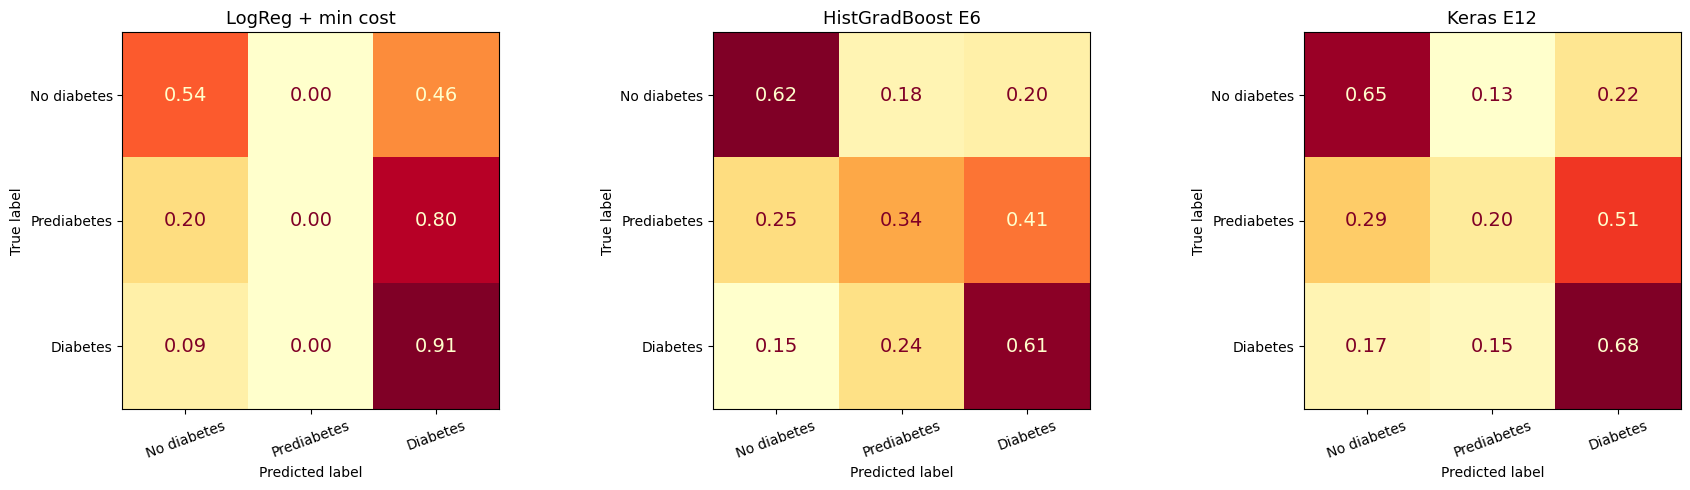

In [29]:
from sklearn.metrics import ConfusionMatrixDisplay

labels = ["No diabetes", "Prediabetes", "Diabetes"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, name in zip(axes, preds):
    ConfusionMatrixDisplay.from_predictions(
        yt, preds[name], ax=ax, display_labels=labels,
        normalize="true", values_format=".2f",
        cmap="YlOrRd", colorbar=False)
    ax.set_title(name, fontsize=13)
    ax.tick_params(axis="x", rotation=20)
    for text in ax.texts:
        text.set_fontsize(14)
plt.tight_layout()
plt.savefig(FOLDER + "confusion_matrices.png", dpi=200, bbox_inches="tight")
plt.show()

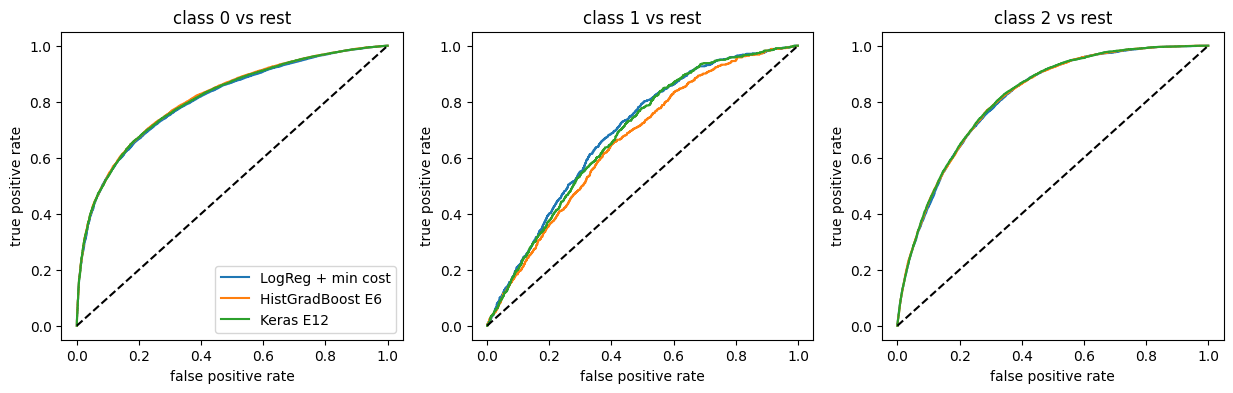

In [33]:
from sklearn.metrics import roc_curve

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for k, ax in enumerate(axes):
    for name in probas:
        fpr, tpr, _ = roc_curve(yt == k, probas[name][:, k])
        ax.plot(fpr, tpr, label=name)
    ax.plot([0, 1], [0, 1], "k--")
    ax.set_title(f"class {k} vs rest")
    ax.set_xlabel("false positive rate")
    ax.set_ylabel("true positive rate")
axes[0].legend()
plt.savefig(FOLDER + "roc_curves.png", dpi=200, bbox_inches="tight")
plt.show()

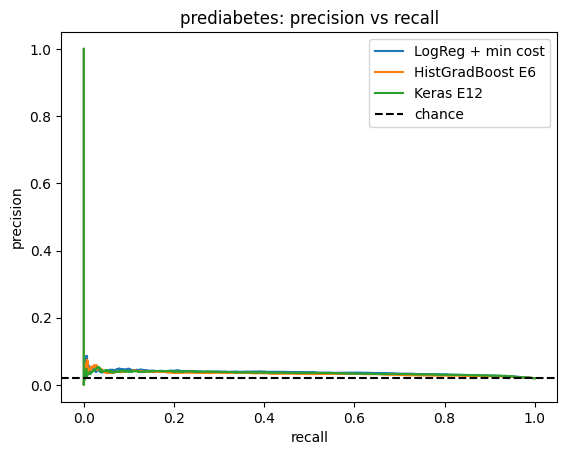

In [32]:
from sklearn.metrics import precision_recall_curve

for name in probas:
    prec, rec, _ = precision_recall_curve(yt == 1, probas[name][:, 1])
    plt.plot(rec, prec, label=name)
plt.axhline((yt == 1).mean(), color="k", linestyle="--", label="chance")
plt.xlabel("recall")
plt.ylabel("precision")
plt.title("prediabetes: precision vs recall")
plt.legend()
plt.savefig(FOLDER + "pr_curve_prediabetes.png", dpi=200, bbox_inches="tight")
plt.show()

In [34]:
from google.colab import drive
drive.mount('/content/drive')

import joblib
OUT = "/content/drive/MyDrive/diabetes_ml_project/"

joblib.dump(lr_base, OUT + "logreg_best.joblib")
joblib.dump({"scaler": scaler, "bmi_cap": bmi_cap, "scale_cols": scale_cols}, OUT + "preprocessing.joblib")
nn12.save(OUT + "keras_best.keras")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Mounted at /content/drive
E4 trees used: 31


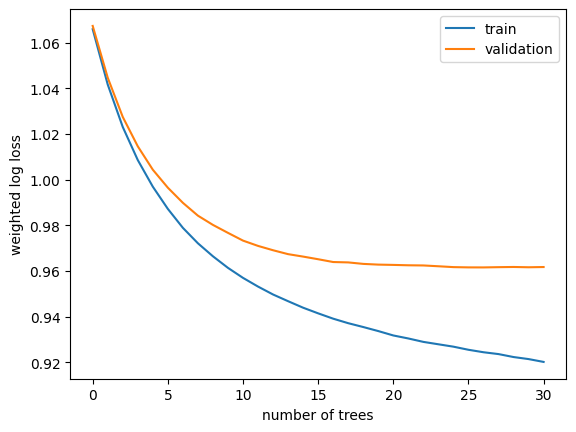

In [5]:
from google.colab import drive
drive.mount('/content/drive')

import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import log_loss
from sklearn.utils.class_weight import compute_sample_weight

FOLDER = "/content/drive/MyDrive/diabetes_ml_project/"
SEED = 42

# same data, cleaning and split as the main notebook
with zipfile.ZipFile(FOLDER + "diabetes_raw_dataset.zip") as z:
    df = pd.read_csv(z.open("diabetes_012_health_indicators_BRFSS2015.csv"))
df = df.drop_duplicates().reset_index(drop=True)
X, y = df.drop(columns="Diabetes_012"), df["Diabetes_012"].astype(int)
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, _, y_val, _ = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

# cap BMI and scale (fit on train only)
cap = X_train["BMI"].quantile(0.995)
cols = ["BMI", "MentHlth", "PhysHlth", "GenHlth", "Age", "Education", "Income"]
X_train_s, X_val_s = X_train.copy(), X_val.copy()
for part in (X_train_s, X_val_s):
    part["BMI"] = part["BMI"].clip(upper=cap)
scaler = StandardScaler()
X_train_s[cols] = scaler.fit_transform(X_train_s[cols])
X_val_s[cols] = scaler.transform(X_val_s[cols])

# E4 boosting, stops by itself
gb = HistGradientBoostingClassifier(learning_rate=0.1, max_iter=200, max_depth=6,
                                    class_weight="balanced", random_state=SEED)
gb.fit(X_train_s, y_train)
print("E4 trees used:", gb.n_iter_)

# loss after each tree
w_tr = compute_sample_weight("balanced", y_train)
w_va = compute_sample_weight("balanced", y_val)
tr_loss = [log_loss(y_train, p, sample_weight=w_tr) for p in gb.staged_predict_proba(X_train_s)]
va_loss = [log_loss(y_val, p, sample_weight=w_va) for p in gb.staged_predict_proba(X_val_s)]

plt.plot(tr_loss, label="train")
plt.plot(va_loss, label="validation")
plt.xlabel("number of trees")
plt.ylabel("weighted log loss")
plt.legend()
plt.savefig(FOLDER + "boosting_learning_curve_E4.png", dpi=200, bbox_inches="tight")
plt.show()